# Canada Immigration (1980–2013) — Complete Exploratory Data Analysis
**Dataset:** United Nations immigration to Canada by citizenship, 1980–2013  
**Scope:** Data understanding, quality audit, preprocessing, descriptive statistics, and exploratory visualization. **No predictive models are built.**



## 1. Libraries and reproducibility
All visualizations are descriptive. Counts refer to the source's immigrant measure, not rates or population-adjusted values.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 6), 'axes.titlesize': 14, 'axes.labelsize': 11})
OUT = Path('outputs'); OUT.mkdir(exist_ok=True)
YEARS = list(range(1980, 2014))
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=170, bbox_inches='tight')
    plt.show()


Python: 3.13.18 | pandas: 2.2.3


## 2. Read the original Excel workbook
The `Canada by Citizenship` sheet contains metadata above the table and footnotes below it. We retain the source data without altering it.

In [2]:
source = Path('Canada.xlsx')
if not source.exists():
    alternatives = [Path('/content/Canada.xlsx'), Path('Canada(7).xlsx'), Path('/mnt/data/Canada(7).xlsx')]
    source = next((p for p in alternatives if p.exists()), source)
if not source.exists():
    try:
        from google.colab import files
        print('Please upload Canada.xlsx')
        uploaded = files.upload()
        source = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError('Place Canada.xlsx beside the notebook and run again.')
raw = pd.read_excel(source, sheet_name='Canada by Citizenship', skiprows=range(20), skipfooter=2)
print('Source:', source, '| Rows:', len(raw), '| Columns:', len(raw.columns))
display(raw.head(4))
print('Column names:', list(raw.columns))


Please upload Canada.xlsx


Saving Canada.xlsx to Canada.xlsx
Source: Canada.xlsx | Rows: 195 | Columns: 43


,Type,Coverage,OdName,AREA,AreaName,REG,RegName,DEV,DevName,1980,...,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
0,Immigrants,Foreigners,Afghanistan,935,Asia,5501,Southern Asia,902,Developing regions,16,...,2978,3436,3009,2652,2111,1746,1758,2203,2635,2004
1,Immigrants,Foreigners,Albania,908,Europe,925,Southern Europe,901,Developed regions,1,...,1450,1223,856,702,560,716,561,539,620,603
2,Immigrants,Foreigners,Algeria,903,Africa,912,Northern Africa,902,Developing regions,80,...,3616,3626,4807,3623,4005,5393,4752,4325,3774,4331
3,Immigrants,Foreigners,American Samoa,909,Oceania,957,Polynesia,902,Developing regions,0,...,0,0,1,0,0,0,0,0,0,0


Column names: ['Type', 'Coverage', 'OdName', 'AREA', 'AreaName', 'REG', 'RegName', 'DEV', 'DevName', 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]


## 3. Data dictionary and structure
Each record represents an origin country or territory; annual columns contain the number of immigrants to Canada in each calendar year. `Total` will be computed as a sum, **not** taken from the source. `DevName` is the source's development grouping; it should not be interpreted as an up-to-date economic classification.

In [3]:
dictionary = pd.DataFrame({
    'Field': ['Country','Continent','Region','DevName','1980 … 2013','Total'],
    'Meaning': ['Origin country/territory','Source geographic continent','Source geographic region',
                'Source development category','Annual immigrant counts (34 years)',
                'Sum of annual counts for each country/territory'],
    'Type': ['category','category','category','category','nonnegative integer','nonnegative integer']
})
display(dictionary)
print('Source types:'); display(raw.dtypes.astype(str).value_counts().rename_axis('dtype').to_frame('columns'))


,Field,Meaning,Type
0,Country,Origin country/territory,category
1,Continent,Source geographic continent,category
2,Region,Source geographic region,category
3,DevName,Source development category,category
4,1980 … 2013,Annual immigrant counts (34 years),nonnegative integer
5,Total,Sum of annual counts for each country/territory,nonnegative integer


Source types:


,columns
dtype,
int64,37
object,6


## 4. Quality audit **before** cleaning
Inspect missing values, unexpected text, duplicates, negative counts, and category completeness. Missing does **not** automatically mean zero.

In [4]:
keep = ['OdName','AreaName','RegName','DevName'] + YEARS
assert set(keep).issubset(raw.columns), 'Unexpected source schema'
audit = raw[keep].copy()
audit = audit.rename(columns={'OdName':'Country','AreaName':'Continent','RegName':'Region'})
textcols = ['Country','Continent','Region','DevName']
numeric_raw = audit[YEARS].apply(pd.to_numeric, errors='coerce')
non_numeric = ((audit[YEARS].notna()) & (numeric_raw.isna())).sum().sum()
print('Exact duplicate records:', audit.duplicated().sum())
print('Duplicate country labels:', audit['Country'].duplicated().sum())
print('Missing text cells:', audit[textcols].isna().sum().to_dict())
print('Missing year cells:', int(audit[YEARS].isna().sum().sum()))
print('Non-numeric, nonmissing year cells:', int(non_numeric))
print('Negative annual counts:', int((numeric_raw < 0).sum().sum()))
print('Fractional annual counts:', int(((numeric_raw % 1 != 0) & numeric_raw.notna()).sum().sum()))
display(audit[textcols].nunique().to_frame('Unique categories'))
display(audit.isna().sum().loc[lambda s: s > 0].to_frame('Missing values'))


Exact duplicate records: 0
Duplicate country labels: 0
Missing text cells: {'Country': 0, 'Continent': 0, 'Region': 0, 'DevName': 0}
Missing year cells: 0
Non-numeric, nonmissing year cells: 0
Negative annual counts: 0
Fractional annual counts: 0


,Unique categories
Country,195
Continent,6
Region,22
DevName,2


,Missing values


## 5. Cleaning and transformation decisions
We strip whitespace from labels, convert yearly fields to numeric, and calculate totals. **No imputation is performed unless the audit shows it is required.** If annual missing or invalid values exist, the notebook stops for investigation rather than silently treating them as zero. No outliers are removed: large migration counts may be genuine observations.

In [5]:
immigration = audit.copy()
for c in textcols:
    immigration[c] = immigration[c].astype('string').str.strip()
if numeric_raw.isna().any().any():
    bad = numeric_raw.isna().stack().loc[lambda s: s].index.tolist()[:12]
    raise ValueError(f'Annual values need source investigation; examples: {bad}')
if (numeric_raw < 0).any().any() or ((numeric_raw % 1 != 0) & numeric_raw.notna()).any().any():
    raise ValueError('Negative or fractional counts require investigation.')
immigration[YEARS] = numeric_raw.astype('int64')
if immigration[textcols].isna().any().any() or immigration['Country'].duplicated().any():
    raise ValueError('Missing or duplicated identifiers need investigation.')
immigration['Total'] = immigration[YEARS].sum(axis=1)
immigration = immigration.sort_values('Country').reset_index(drop=True)
assert immigration['Total'].eq(immigration[YEARS].sum(axis=1)).all()
assert len(immigration) == len(raw)
immigration.to_csv(OUT / 'Canada_Immigration_Cleaned_1980_2013.csv', index=False)
print('Cleaned table:', immigration.shape, '| Total immigrants:', f"{immigration['Total'].sum():,}")
display(immigration.head())


Cleaned table: (195, 39) | Total immigrants: 6,409,153


,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


## 6. Descriptive statistics and distribution
Because country totals are strongly skewed, we report the median and IQR in addition to the mean and standard deviation.

In [6]:
display(immigration['Total'].describe(percentiles=[.10,.25,.50,.75,.90,.95,.99]).to_frame('Country cumulative immigration'))
print('Skewness:', round(immigration['Total'].skew(), 2))
print('Countries with zero cumulative counts:', int(immigration['Total'].eq(0).sum()))
display(immigration.groupby('Continent').agg(Countries=('Country','size'), Immigrants=('Total','sum'),
                                              Median_country_total=('Total','median')).sort_values('Immigrants', ascending=False))


,Country cumulative immigration
count,195.000000
mean,32867.451282
std,91785.498686
min,1.000000
10%,91.800000
25%,952.000000
50%,5018.000000
75%,22239.500000
90%,72195.400000
95%,122523.600000


Skewness: 5.43
Countries with zero cumulative counts: 0


,Countries,Immigrants,Median_country_total
Continent,,,
Asia,49,3317794,8490.0
Europe,43,1410947,5963.0
Latin America and the Caribbean,33,765148,11193.0
Africa,54,618948,2805.5
Northern America,2,241142,120571.0
Oceania,14,55174,16.5


## 7. Visualization 1 — Annual immigration trend
This chart answers whether the annual flow increased, decreased, or fluctuated. Interpret the shape descriptively; do not assume causation.

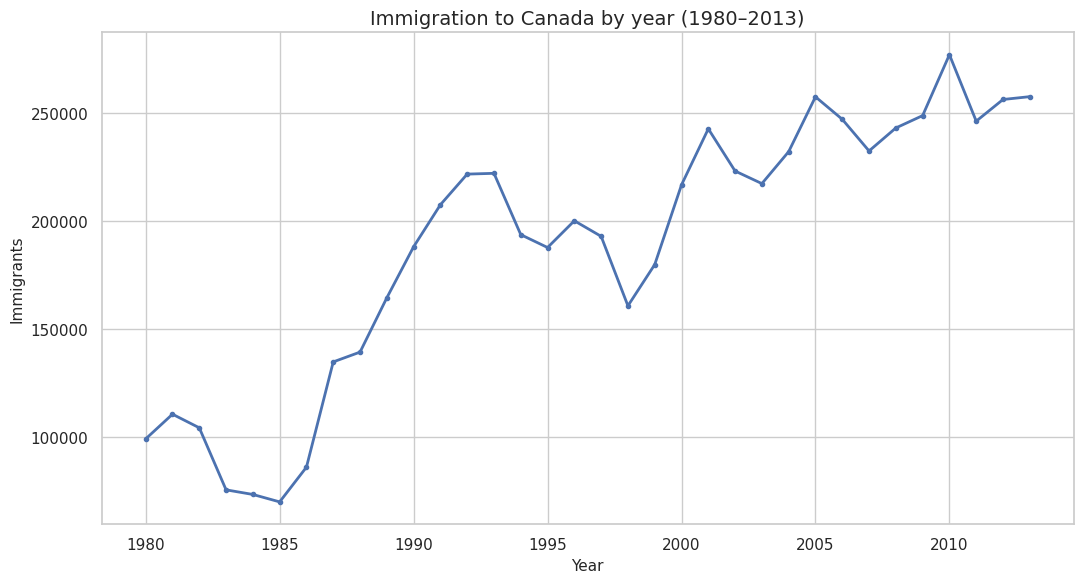

Lowest year: 1985 (69,978); highest year: 2010 (276,956).
1980: 99,137; 2013: 257,537; difference: +158,400.


In [7]:
annual = immigration[YEARS].sum(axis=0)
fig, ax = plt.subplots()
ax.plot(YEARS, annual.values, marker='o', markersize=3, linewidth=2)
ax.set(title='Immigration to Canada by year (1980–2013)', xlabel='Year', ylabel='Immigrants')
ax.ticklabel_format(style='plain', axis='y')
savefig('01_annual_trend.png')
print(f'Lowest year: {annual.idxmin()} ({annual.min():,}); highest year: {annual.idxmax()} ({annual.max():,}).')
print(f'1980: {annual.loc[1980]:,}; 2013: {annual.loc[2013]:,}; difference: {annual.loc[2013]-annual.loc[1980]:+,}.')


## 8. Visualization 2 — Top 15 origin countries
The ranking uses cumulative counts over all 34 years, not a single year's immigration.

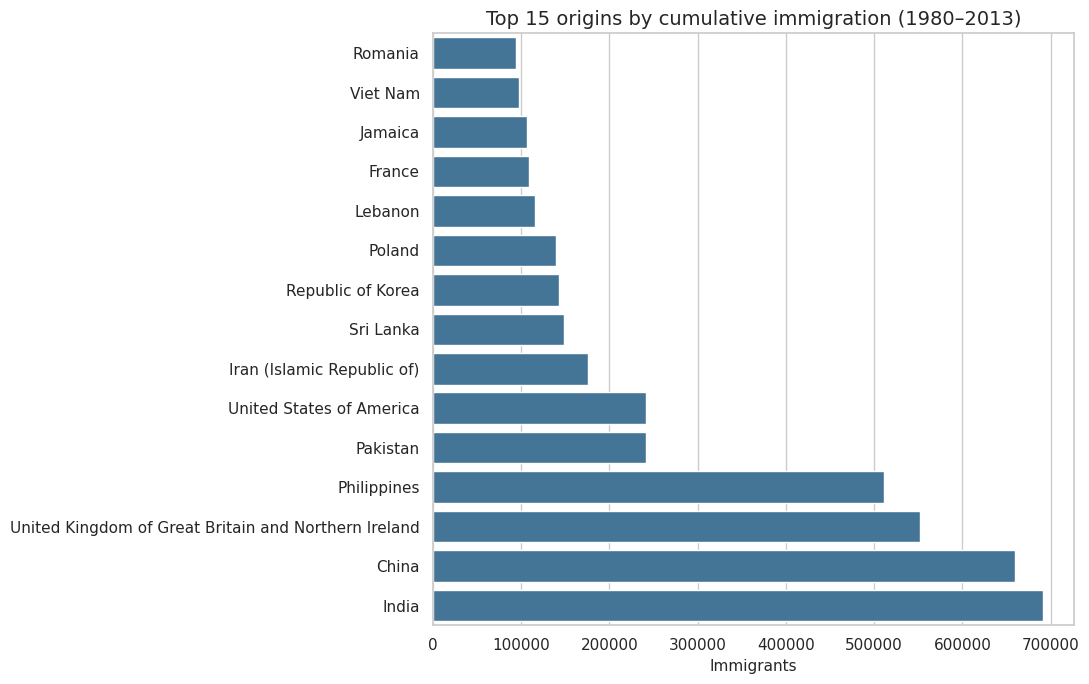

,Country,Total
79,India,691904
36,China,659962
183,United Kingdom of Great Britain and Northern I...,551500
136,Philippines,511391
130,Pakistan,241600
185,United States of America,241122
81,Iran (Islamic Republic of),175923
162,Sri Lanka,148358
140,Republic of Korea,142581
137,Poland,139241


Top 5 share of all immigrants: 41.4%


In [8]:
top15 = immigration.nlargest(15, 'Total').sort_values('Total')
fig, ax = plt.subplots(figsize=(11,7))
sns.barplot(data=top15, x='Total', y='Country', ax=ax, color='#3677a5')
ax.set(title='Top 15 origins by cumulative immigration (1980–2013)', xlabel='Immigrants', ylabel='')
savefig('02_top_origins.png')
display(top15[['Country','Total']].sort_values('Total',ascending=False).head(10))
print('Top 5 share of all immigrants:', f"{immigration.nlargest(5,'Total')['Total'].sum()/immigration['Total'].sum():.1%}")


## 9. Visualization 3 — Immigration by continent
Compare continent totals; these are absolute counts, not per-capita rates.

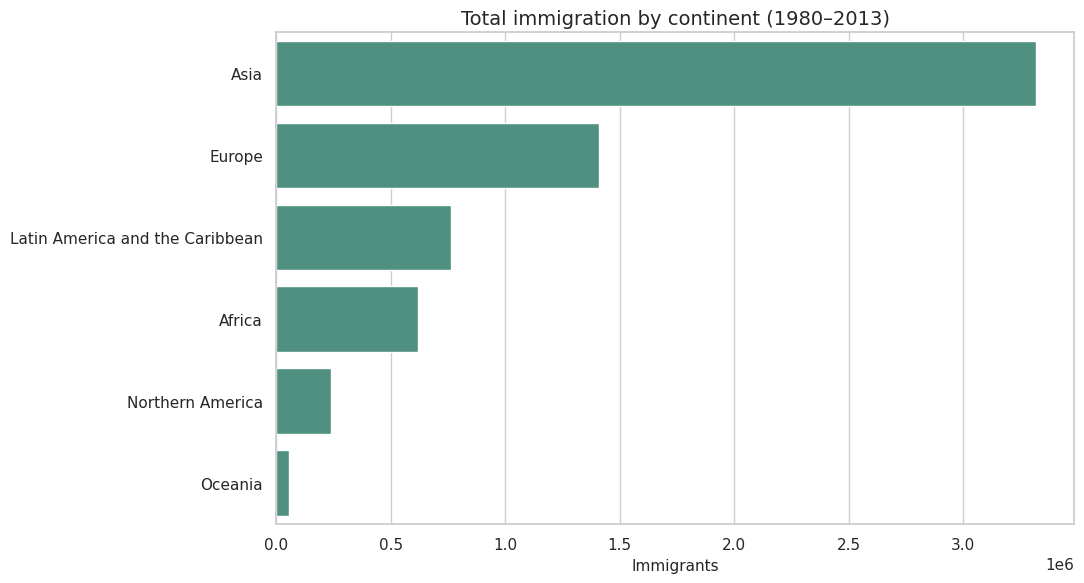

Largest contributing continent: Asia | Share: 51.8%


In [9]:
continents = immigration.groupby('Continent')['Total'].sum().sort_values(ascending=False)
fig, ax = plt.subplots()
sns.barplot(x=continents.values, y=continents.index, ax=ax, color='#459b86')
ax.set(title='Total immigration by continent (1980–2013)', xlabel='Immigrants', ylabel='')
savefig('03_continent_totals.png')
print('Largest contributing continent:', continents.index[0], '| Share:', f'{continents.iloc[0]/continents.sum():.1%}')


## 10. Visualization 4 — Continental shares
The shares sum to 100% of recorded immigrants across all origins in this dataset.

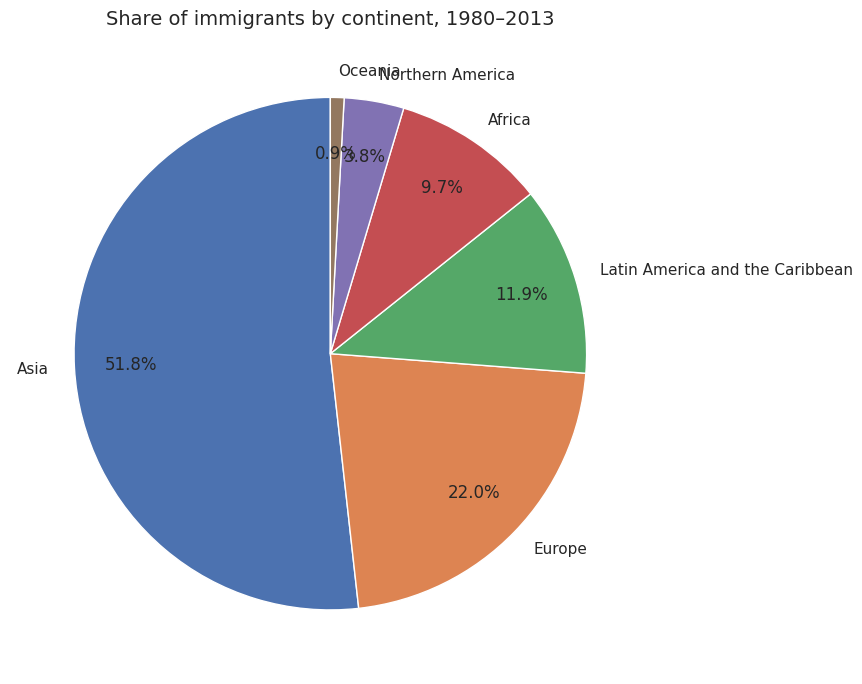

Shares (%):


,Percent
Continent,
Asia,51.77
Europe,22.01
Latin America and the Caribbean,11.94
Africa,9.66
Northern America,3.76
Oceania,0.86


In [10]:
fig, ax = plt.subplots(figsize=(9,7))
ax.pie(continents.values, labels=continents.index, autopct='%1.1f%%', startangle=90, pctdistance=.78)
ax.set_title('Share of immigrants by continent, 1980–2013')
savefig('04_continent_share.png')
print('Shares (%):'); display((continents/continents.sum()*100).round(2).to_frame('Percent'))


## 11. Visualization 5 — Heatmap of continent-by-year counts
This view reveals both time trends and differences in absolute scale among continents.

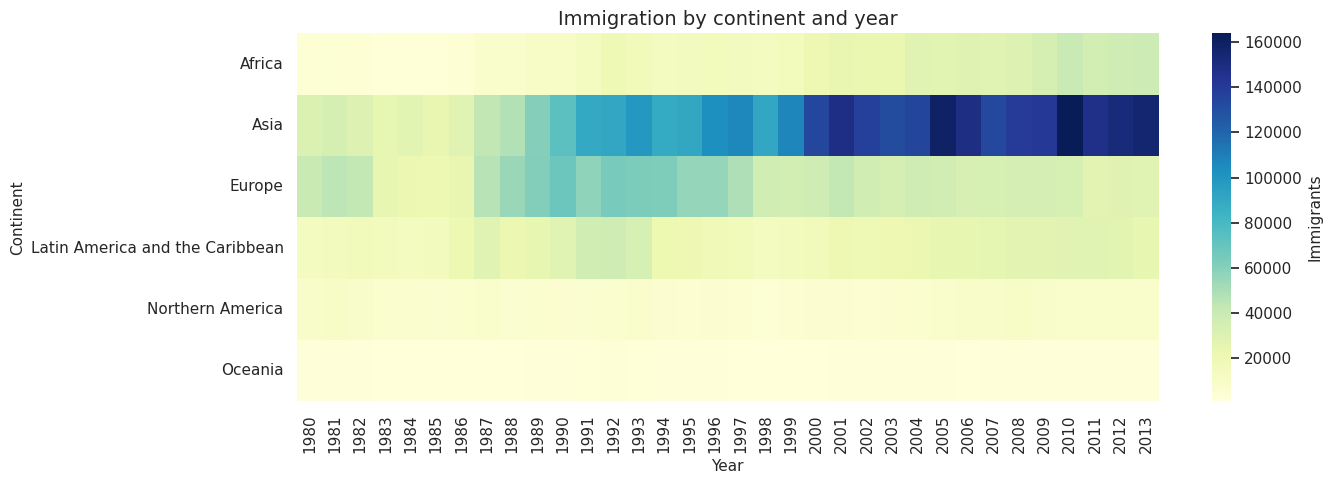

Highest continent-year count: ('Asia', 2010) (163,845)


In [11]:
continent_year = immigration.groupby('Continent')[YEARS].sum()
fig, ax = plt.subplots(figsize=(14,5))
sns.heatmap(continent_year, cmap='YlGnBu', ax=ax, cbar_kws={'label':'Immigrants'})
ax.set(title='Immigration by continent and year', xlabel='Year', ylabel='Continent')
savefig('05_continent_year_heatmap.png')
print('Highest continent-year count:', continent_year.stack().idxmax(), f'({continent_year.stack().max():,})')


## 12. Visualization 6 — Stacked area chart
This shows how continents contributed to the total each year. The stack height equals total annual immigration.

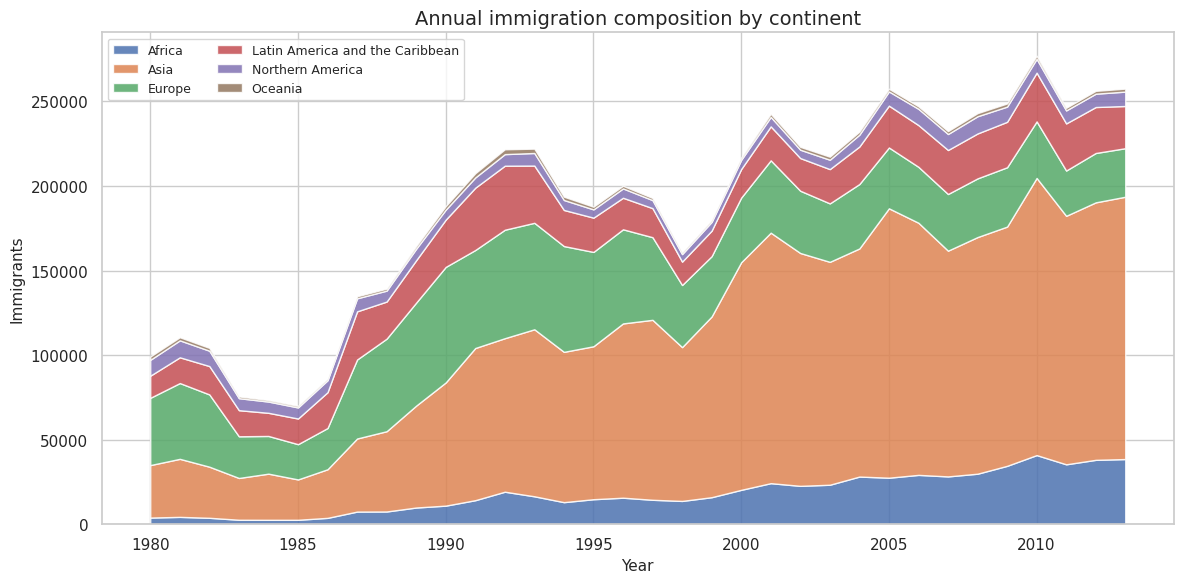

The stacked total in 2013: 257,537 | Annual dataset total: 257,537


In [12]:
fig, ax = plt.subplots(figsize=(12,6))
ax.stackplot(YEARS, *[continent_year.loc[c].values for c in continent_year.index],
             labels=continent_year.index, alpha=.85)
ax.set(title='Annual immigration composition by continent', xlabel='Year', ylabel='Immigrants')
ax.legend(loc='upper left', ncol=2, fontsize=9)
savefig('06_stacked_continents.png')
print('The stacked total in 2013:', f'{continent_year[2013].sum():,}', '| Annual dataset total:', f'{annual.loc[2013]:,}')


## 13. Visualization 7 — Distribution and outlier audit
The IQR rule flags statistically unusual country totals; flagged countries are **not deleted**, because high counts may be meaningful. A log1p transformation is used **for visualization only**, preserving zero totals.

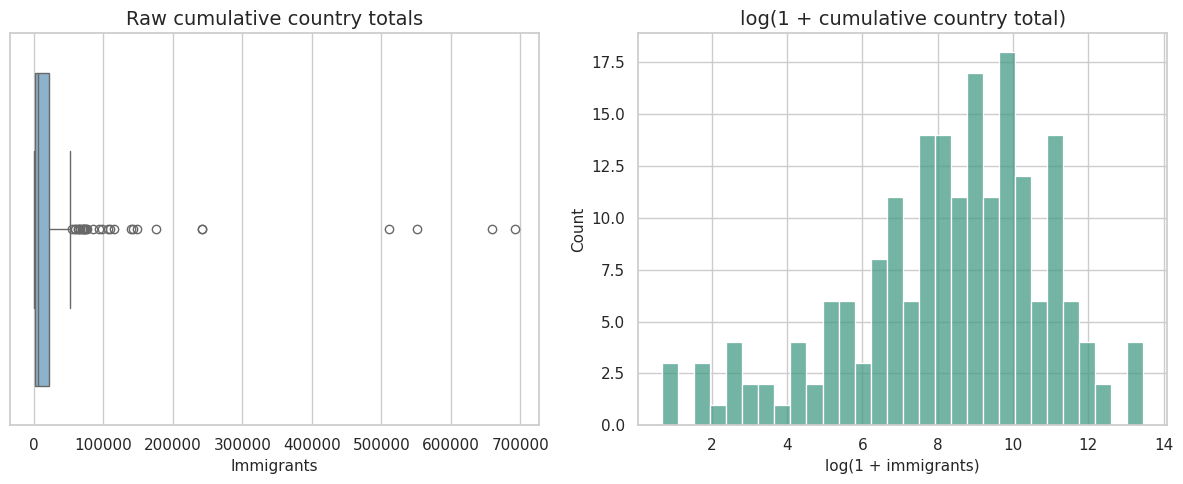

IQR upper fence: 54,170.8; flagged countries: 30.


,Country,Continent,Total
79,India,Asia,691904
36,China,Asia,659962
183,United Kingdom of Great Britain and Northern I...,Europe,551500
136,Philippines,Asia,511391
130,Pakistan,Asia,241600
185,United States of America,Northern America,241122
81,Iran (Islamic Republic of),Asia,175923
162,Sri Lanka,Asia,148358
140,Republic of Korea,Asia,142581
137,Poland,Europe,139241


In [13]:
q1, q3 = immigration['Total'].quantile([.25,.75])
iqr = q3-q1
upper = q3 + 1.5*iqr
outliers = immigration[immigration['Total'] > upper].sort_values('Total', ascending=False)
fig, axes = plt.subplots(1,2,figsize=(12,5))
sns.boxplot(x=immigration['Total'], ax=axes[0], color='#83b4d6')
axes[0].set(title='Raw cumulative country totals', xlabel='Immigrants')
sns.histplot(np.log1p(immigration['Total']), bins=30, ax=axes[1], color='#459b86')
axes[1].set(title='log(1 + cumulative country total)', xlabel='log(1 + immigrants)')
plt.tight_layout(); plt.savefig(OUT/'07_distribution_outliers.png', dpi=170, bbox_inches='tight'); plt.show()
print(f'IQR upper fence: {upper:,.1f}; flagged countries: {len(outliers)}.')
display(outliers[['Country','Continent','Total']].head(15))


## 14. Visualization 8 — Developed versus developing classification
The category labels are taken from the original dataset and are not reassigned or updated.

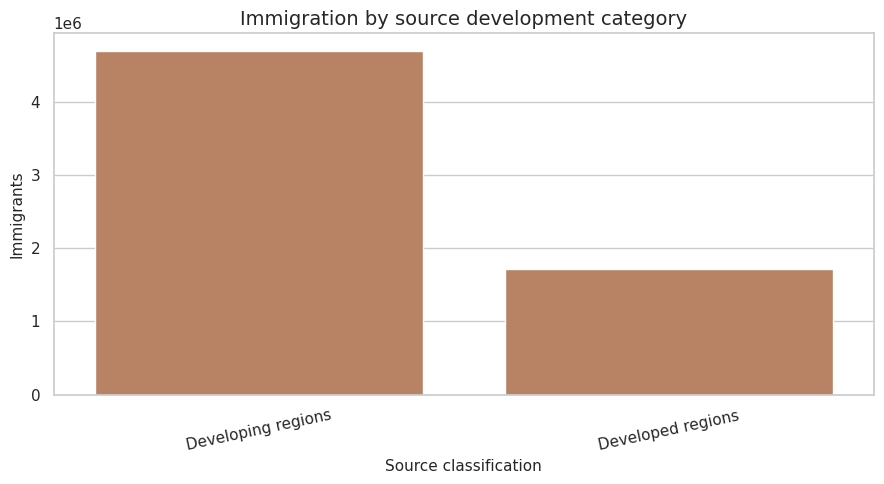

,Immigrants
DevName,
Developing regions,4695142
Developed regions,1714011


In [14]:
development = immigration.groupby('DevName')['Total'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9,5))
sns.barplot(x=development.index, y=development.values, ax=ax, color='#c67e56')
ax.set(title='Immigration by source development category', xlabel='Source classification', ylabel='Immigrants')
ax.tick_params(axis='x', rotation=12)
savefig('08_development_categories.png')
display(development.to_frame('Immigrants'))


## 15. Visualization 9 — Leading regions
This comparison reveals subcontinental patterns that continent totals may hide.

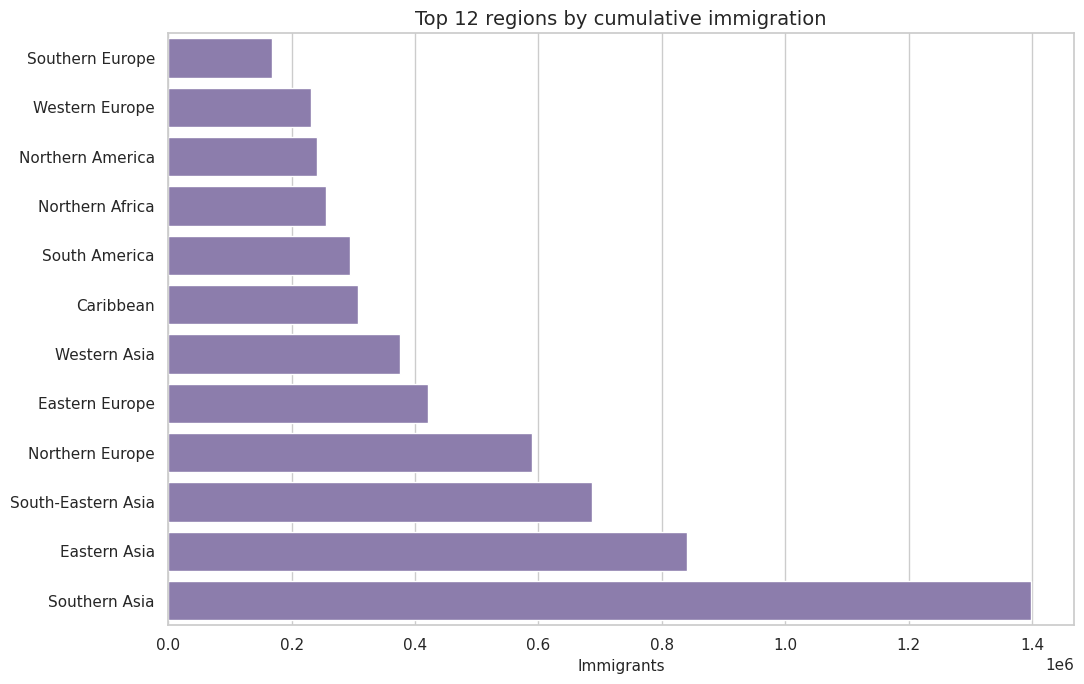

Leading region: Southern Asia (1,398,120 immigrants)


In [15]:
regions = immigration.groupby('Region')['Total'].sum().nlargest(12).sort_values()
fig, ax = plt.subplots(figsize=(11,7))
sns.barplot(x=regions.values, y=regions.index, ax=ax, color='#8975b4')
ax.set(title='Top 12 regions by cumulative immigration', xlabel='Immigrants', ylabel='')
savefig('09_top_regions.png')
print('Leading region:', regions.idxmax(), f'({regions.max():,} immigrants)')


## 16. Additional bivariate analysis — Year-to-year change
Annual differences are descriptive, and can be affected by changing policy, demographics, reporting, and other factors not observed here.

In [16]:
changes = annual.diff()
display(pd.DataFrame({'Annual_count':annual, 'Change_from_previous_year':changes}).tail(12))
print('Largest annual rise:', int(changes.idxmax()), f'({changes.max():+,.0f})')
print('Largest annual fall:', int(changes.idxmin()), f'({changes.min():+,.0f})')


,Annual_count,Change_from_previous_year
2002,223111,-19532.0
2003,217297,-5814.0
2004,232083,14786.0
2005,257457,25374.0
2006,247057,-10400.0
2007,232405,-14652.0
2008,243047,10642.0
2009,248768,5721.0
2010,276956,28188.0
2011,246194,-30762.0


Largest annual rise: 1987 (+48,723)
Largest annual fall: 1998 (-32,158)


## 17. Findings, limitations, and conclusion
The following statements are generated from the observed dataset. They describe associations and patterns only, not causes.

In [17]:
leader = immigration.nlargest(1,'Total').iloc[0]
print('KEY FINDINGS')
print(f'1. The dataset covers {len(immigration)} origin countries/territories over {len(YEARS)} years.')
print(f'2. Recorded cumulative immigration: {immigration.Total.sum():,}.')
print(f'3. Peak annual count: {annual.idxmax()} ({annual.max():,}); minimum: {annual.idxmin()} ({annual.min():,}).')
print(f'4. Leading origin: {leader.Country} ({leader.Total:,}).')
print(f'5. Leading continent: {continents.index[0]} ({continents.iloc[0]:,}; {continents.iloc[0]/continents.sum():.1%}).')
print(f'6. IQR flags {len(outliers)} unusually high country totals; none were removed.')
print('LIMITATIONS: counts are not rates; dataset ends in 2013; classifications are historical;')
print('the analysis is observational and cannot establish why migration changed.')


KEY FINDINGS
1. The dataset covers 195 origin countries/territories over 34 years.
2. Recorded cumulative immigration: 6,409,153.
3. Peak annual count: 2010 (276,956); minimum: 1985 (69,978).
4. Leading origin: India (691,904).
5. Leading continent: Asia (3,317,794; 51.8%).
6. IQR flags 30 unusually high country totals; none were removed.
LIMITATIONS: counts are not rates; dataset ends in 2013; classifications are historical;
the analysis is observational and cannot establish why migration changed.
